# MLB win prediction after 6 innings

Retrosheet 2025 play-by-play data (`2025plays.csv`). Uses the score after 6 innings to predict the winner and the chance of that result, with three models:

- **Unsupervised:** k-means clustering of game states
- **Supervised 1:** win-rate lookup table by run differential
- **Supervised 2:** logistic regression

All three are compared on the same held-out games.

## Setup
Set `DATA_PATH` to where `2025plays.csv` lives. Charts are shown inline and also saved to `OUT_DIR`.

In [36]:
%matplotlib inline
import os

import matplotlib
import matplotlib.ticker
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, brier_score_loss, log_loss, silhouette_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

DATA_PATH = "C:\\Users\\tunab\\OneDrive\\Documents\\Capstone\\2025plays\\2025plays.csv"
OUT_DIR = "figures"
RANDOM_STATE = 42
N_CLUSTERS = 3          # change to try other k values (silhouette scores are printed)
DIFF_CAP = 6            # lookup table: run diffs beyond +/-6 are pooled

# Chart styling
HOME_COLOR = "#2a78d6"   # blue
AWAY_COLOR = "#eb6834"   # orange
CLUSTER_COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]  # first 3 categorical slots
INK, INK_MUTED, GRID, AXIS = "#1f1f1d", "#6b6a63", "#e1e0d9", "#c3c2b7"

# ID / text columns that should stay as strings
STR_COLS = [
    "gid", "event", "site", "batteam", "pitteam", "batter", "pitcher",
    "bathand", "pithand", "count", "pitches", "loc", "hittype",
    "umphome", "ump1b", "ump2b", "ump3b", "umplf", "umprf",
    "gametype", "pbp",
]

## 1. Load and preprocess
`load_plays()` reads the CSV with text types for ID columns; `preprocess()` parses dates, sets categories and adds helper columns; `check_load()` runs sanity checks.

In [14]:
def load_plays(path: str = DATA_PATH) -> pd.DataFrame:
    """Read the raw CSV with explicit string types for ID/text columns."""
    return pd.read_csv(path, dtype={c: "string" for c in STR_COLS}, low_memory=False)


def preprocess(df: pd.DataFrame, regular_season_only: bool = False) -> pd.DataFrame:
    """Basic cleaning: parse dates, set categories, add helper columns."""
    df = df.copy()

    # Dates stored as YYYYMMDD integers
    df["date"] = pd.to_datetime(df["date"].astype(str), format="%Y%m%d")

    # Low-cardinality columns -> category (saves memory)
    for c in ["gametype", "bathand", "pithand", "hittype", "batteam", "pitteam", "site"]:
        df[c] = df[c].astype("category")

    # Boolean-friendly flags
    df["is_home_batting"] = df["vis_home"] == 1
    df["is_top"] = df["top_bot"] == 0

    # Score from batting team's perspective (before the play)
    df["bat_score"] = df["score_h"].where(df["is_home_batting"], df["score_v"])
    df["fld_score"] = df["score_v"].where(df["is_home_batting"], df["score_h"])

    # Keep plays in game order
    df = df.sort_values(["date", "gid"], kind="stable").reset_index(drop=True)

    if regular_season_only:
        df = df[df["gametype"] == "regular"].reset_index(drop=True)

    return df


def check_load(df: pd.DataFrame) -> None:
    """Quick sanity checks to confirm the data loaded properly."""
    print("Shape:", df.shape)
    print("\nFirst 5 rows:")
    print(df.head())
    print("\nGames:", df["gid"].nunique())
    print("Date range:", df["date"].min().date(), "to", df["date"].max().date())
    print("\nGame types:\n", df["gametype"].value_counts())
    assert not df.empty, "DataFrame is empty"
    assert {"gid", "event", "inning", "batter", "pitcher"}.issubset(df.columns), "Missing key columns"

In [15]:
plays = preprocess(load_plays(DATA_PATH))
check_load(plays)

Shape: (193767, 181)

First 5 rows:
            gid   event  inning  top_bot  vis_home   site batteam pitteam  \
0  CHN202503180  43/G34       1        0         0  TOK01     LAN     CHN   
1  CHN202503180   3/P34       1        0         0  TOK01     LAN     CHN   
2  CHN202503180       K       1        0         0  TOK01     LAN     CHN   
3  CHN202503180       W       1        1         1  TOK01     CHN     LAN   
4  CHN202503180  6/L6MD       1        1         1  TOK01     CHN     LAN   

   score_v  score_h  ...     ump3b umplf  umprf       date gametype   pbp  \
0        0        0  ...  libkj901  <NA>   <NA> 2025-03-18  regular  full   
1        0        0  ...  libkj901  <NA>   <NA> 2025-03-18  regular  full   
2        0        0  ...  libkj901  <NA>   <NA> 2025-03-18  regular  full   
3        0        0  ...  libkj901  <NA>   <NA> 2025-03-18  regular  full   
4        0        0  ...  libkj901  <NA>   <NA> 2025-03-18  regular  full   

   is_home_batting  is_top bat_score f

## 2. Inning-start scores
Iterates through the plays and keeps the first play of each `(gid, inning)` pair. `score_v`/`score_h` are the score *before* the play, so this is the score at the start of each inning.

In [16]:
def build_inning_scores(df: pd.DataFrame) -> pd.DataFrame:
    """
    Iterate through plays in game order and keep only the first play of each
    (gid, inning) pair. Because score_v/score_h are the score *before* the play,
    that first row is the score at the start of the inning.
    """
    seen = set()
    rows = []
    for gid, inning, score_v, score_h in df[["gid", "inning", "score_v", "score_h"]].itertuples(index=False):
        key = (gid, inning)
        if key not in seen:
            seen.add(key)
            rows.append({"gid": gid, "inning": inning, "score_v": score_v, "score_h": score_h})
    return pd.DataFrame(rows, columns=["gid", "inning", "score_v", "score_h"])

In [17]:
inning_scores = build_inning_scores(plays)
print("Inning-start scores:", inning_scores.shape)
assert not inning_scores.duplicated(["gid", "inning"]).any(), "Duplicate gid/inning rows"
inning_scores.head(10)

Inning-start scores: (22612, 4)


,gid,inning,score_v,score_h
0,CHN202503180,1,0,0
1,CHN202503180,2,0,0
2,CHN202503180,3,0,1
3,CHN202503180,4,0,1
4,CHN202503180,5,0,1
5,CHN202503180,6,3,1
6,CHN202503180,7,3,1
7,CHN202503180,8,3,1
8,CHN202503180,9,3,1
9,CHN202503190,1,0,0


## 3. Game-level modeling table
One row per game: the score after 6 innings (start of the 7th) plus the final result. All-Star games and games that ended before the 7th are dropped.

In [18]:
def build_final_scores(df: pd.DataFrame) -> pd.DataFrame:
    """Final score = score before the last play + runs scored on that play."""
    last = df.groupby("gid", sort=False).tail(1)
    final_v = last["score_v"] + np.where(last["vis_home"] == 0, last["runs"], 0)
    final_h = last["score_h"] + np.where(last["vis_home"] == 1, last["runs"], 0)
    return pd.DataFrame({
        "gid": last["gid"].values,
        "gametype": last["gametype"].astype(str).values,
        "final_v": final_v.values,
        "final_h": final_h.values,
    })


def build_game_table(plays: pd.DataFrame, inning_scores: pd.DataFrame) -> pd.DataFrame:
    """
    One row per game: score after 6 innings (= start of inning 7) and the result.
    Drops All-Star (exhibition) games and games that ended before the 7th.
    """
    after6 = (inning_scores[inning_scores["inning"] == 7]
              .rename(columns={"score_v": "v_after6", "score_h": "h_after6"})
              .drop(columns="inning"))
    games = after6.merge(build_final_scores(plays), on="gid", how="inner")
    games = games[games["gametype"] != "allstar"].copy()

    games["run_diff"] = games["h_after6"] - games["v_after6"]      # + = home leading
    games["total_runs"] = games["h_after6"] + games["v_after6"]
    games["home_win"] = (games["final_h"] > games["final_v"]).astype(int)
    return games.reset_index(drop=True)

In [19]:
games = build_game_table(plays, inning_scores)
print(f"{len(games)} games, home team won {games['home_win'].mean():.1%}")

# Same train/test split for every model
train, test = train_test_split(games, test_size=0.25, random_state=RANDOM_STATE,
                               stratify=games["home_win"])
train, test = train.reset_index(drop=True), test.reset_index(drop=True)
print(f"Train: {len(train)} games | Test: {len(test)} games")
games.head()

2475 games, home team won 54.3%
Train: 1856 games | Test: 619 games


,gid,v_after6,h_after6,gametype,final_v,final_h,run_diff,total_runs,home_win
0,CHN202503180,3,1,regular,4,1,-2,4,0
1,CHN202503190,6,3,regular,6,3,-3,9,0
2,ARI202503270,8,5,regular,10,6,-3,13,0
3,CHA202503270,0,3,regular,1,8,3,3,1
4,CIN202503270,2,3,regular,6,4,1,5,0


## Chart helpers

In [20]:
def style_axes(ax, title, xlabel, ylabel):
    ax.set_title(title, loc="left", fontsize=13, color=INK, pad=12)
    ax.set_xlabel(xlabel, color=INK_MUTED)
    ax.set_ylabel(ylabel, color=INK_MUTED)
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(AXIS)
    ax.tick_params(colors=INK_MUTED, length=0)


def save(fig, out_dir, name):
    os.makedirs(out_dir, exist_ok=True)
    path = os.path.join(out_dir, name)
    fig.tight_layout()
    fig.savefig(path, dpi=150)
    plt.show()
    print(f"  saved {path}")

## 4a. Unsupervised: k-means
Clusters games on run differential and total runs without using the outcome. Each cluster's actual home-win rate becomes its prediction. Change `N_CLUSTERS` in Setup to try other values of k.

In [37]:
KM_FEATURES = ["run_diff", "total_runs"]


def fit_kmeans(train: pd.DataFrame, k: int = N_CLUSTERS):
    """
    Cluster game states on run differential + total runs (no outcome used).
    Afterwards, each cluster's observed home-win rate becomes its prediction.
    """
    scaler = StandardScaler().fit(train[KM_FEATURES])
    X = scaler.transform(train[KM_FEATURES])

    print("  silhouette by k (higher = better-separated clusters):")
    for kk in range(2, 9):
        labels = KMeans(n_clusters=kk, n_init=10, random_state=RANDOM_STATE).fit_predict(X)
        print(f"    k={kk}: {silhouette_score(X, labels):.3f}")

    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X)
    train = train.assign(cluster=km.labels_)
    win_rate = train.groupby("cluster")["home_win"].mean()

    # Relabel clusters 0..k-1 from lowest to highest home-win rate (easier to read)
    order = {old: new for new, old in enumerate(win_rate.sort_values().index)}
    summary = (train.assign(cluster=train["cluster"].map(order))
               .groupby("cluster")
               .agg(games=("gid", "size"), home_win_rate=("home_win", "mean"),
                    avg_run_diff=("run_diff", "mean"), avg_total_runs=("total_runs", "mean")))
    return {"scaler": scaler, "km": km, "order": order, "summary": summary}


def predict_kmeans(model, df: pd.DataFrame) -> np.ndarray:
    raw = model["km"].predict(model["scaler"].transform(df[KM_FEATURES]))
    clusters = pd.Series(raw).map(model["order"])
    return clusters.map(model["summary"]["home_win_rate"]).to_numpy()


def plot_kmeans(model, train: pd.DataFrame, out_dir: str):
    raw = model["km"].predict(model["scaler"].transform(train[KM_FEATURES]))
    clusters = pd.Series(raw).map(model["order"]).to_numpy()
    rng = np.random.default_rng(RANDOM_STATE)
    jitter = lambda n: rng.uniform(-0.3, 0.3, n)  # scores are integers, so spread points

    fig, ax = plt.subplots(figsize=(9, 6))
    for c, row in model["summary"].iterrows():
        m = clusters == c
        color = CLUSTER_COLORS[c % len(CLUSTER_COLORS)]
        ax.scatter(train.loc[m, "run_diff"] + jitter(m.sum()),
                   train.loc[m, "total_runs"] + jitter(m.sum()),
                   s=10, alpha=0.35, color=color, linewidths=0,
                   label=f"Cluster {c}: home wins {row.home_win_rate:.0%} (n={int(row.games)})")
        ax.annotate(f"{row.home_win_rate:.0%}", (row.avg_run_diff, row.avg_total_runs),
                    ha="center", va="center", fontsize=11, color=INK, weight="bold",
                    bbox=dict(boxstyle="round,pad=0.3", fc="white", ec=color, lw=1.5))
    ax.axvline(0, color=AXIS, lw=1)
    style_axes(ax, "K-means clusters of game states after 6 innings",
               "Run differential (home − visitor)", "Total runs scored")
    ax.legend(frameon=False, loc="upper left", fontsize=9, labelcolor=INK)
    save(fig, out_dir, "1_kmeans_clusters.png")

  silhouette by k (higher = better-separated clusters):
    k=2: 0.355
    k=3: 0.434
    k=4: 0.368
    k=5: 0.364
    k=6: 0.380
    k=7: 0.350
    k=8: 0.363


,games,home_win_rate,avg_run_diff,avg_total_runs
cluster,,,,
0,373,0.105,-4.284,9.566
1,1088,0.546,0.152,3.665
2,395,0.949,4.843,9.030


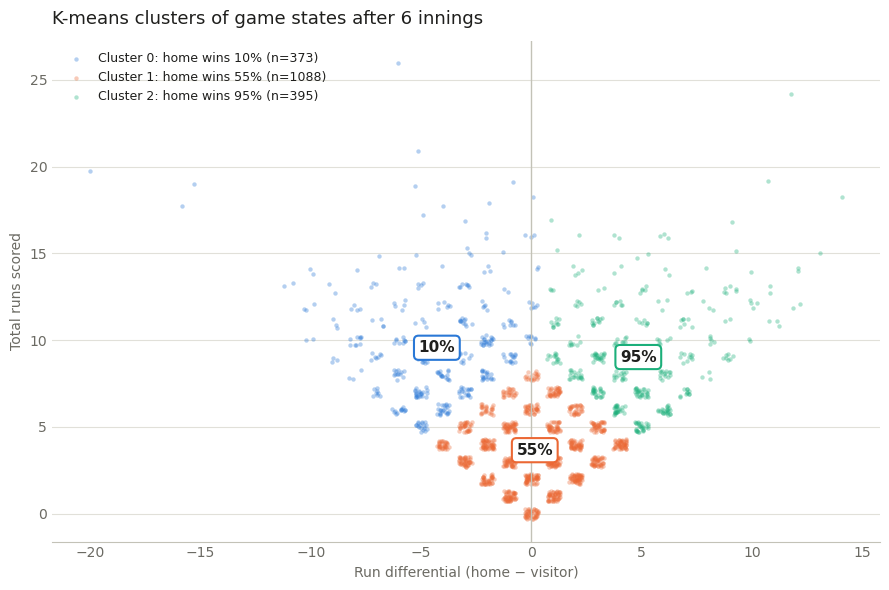

  saved figures\1_kmeans_clusters.png


    k=8: 0.363


,games,home_win_rate,avg_run_diff,avg_total_runs
cluster,,,,
0,373,0.105,-4.284,9.566
1,1088,0.546,0.152,3.665
2,395,0.949,4.843,9.030


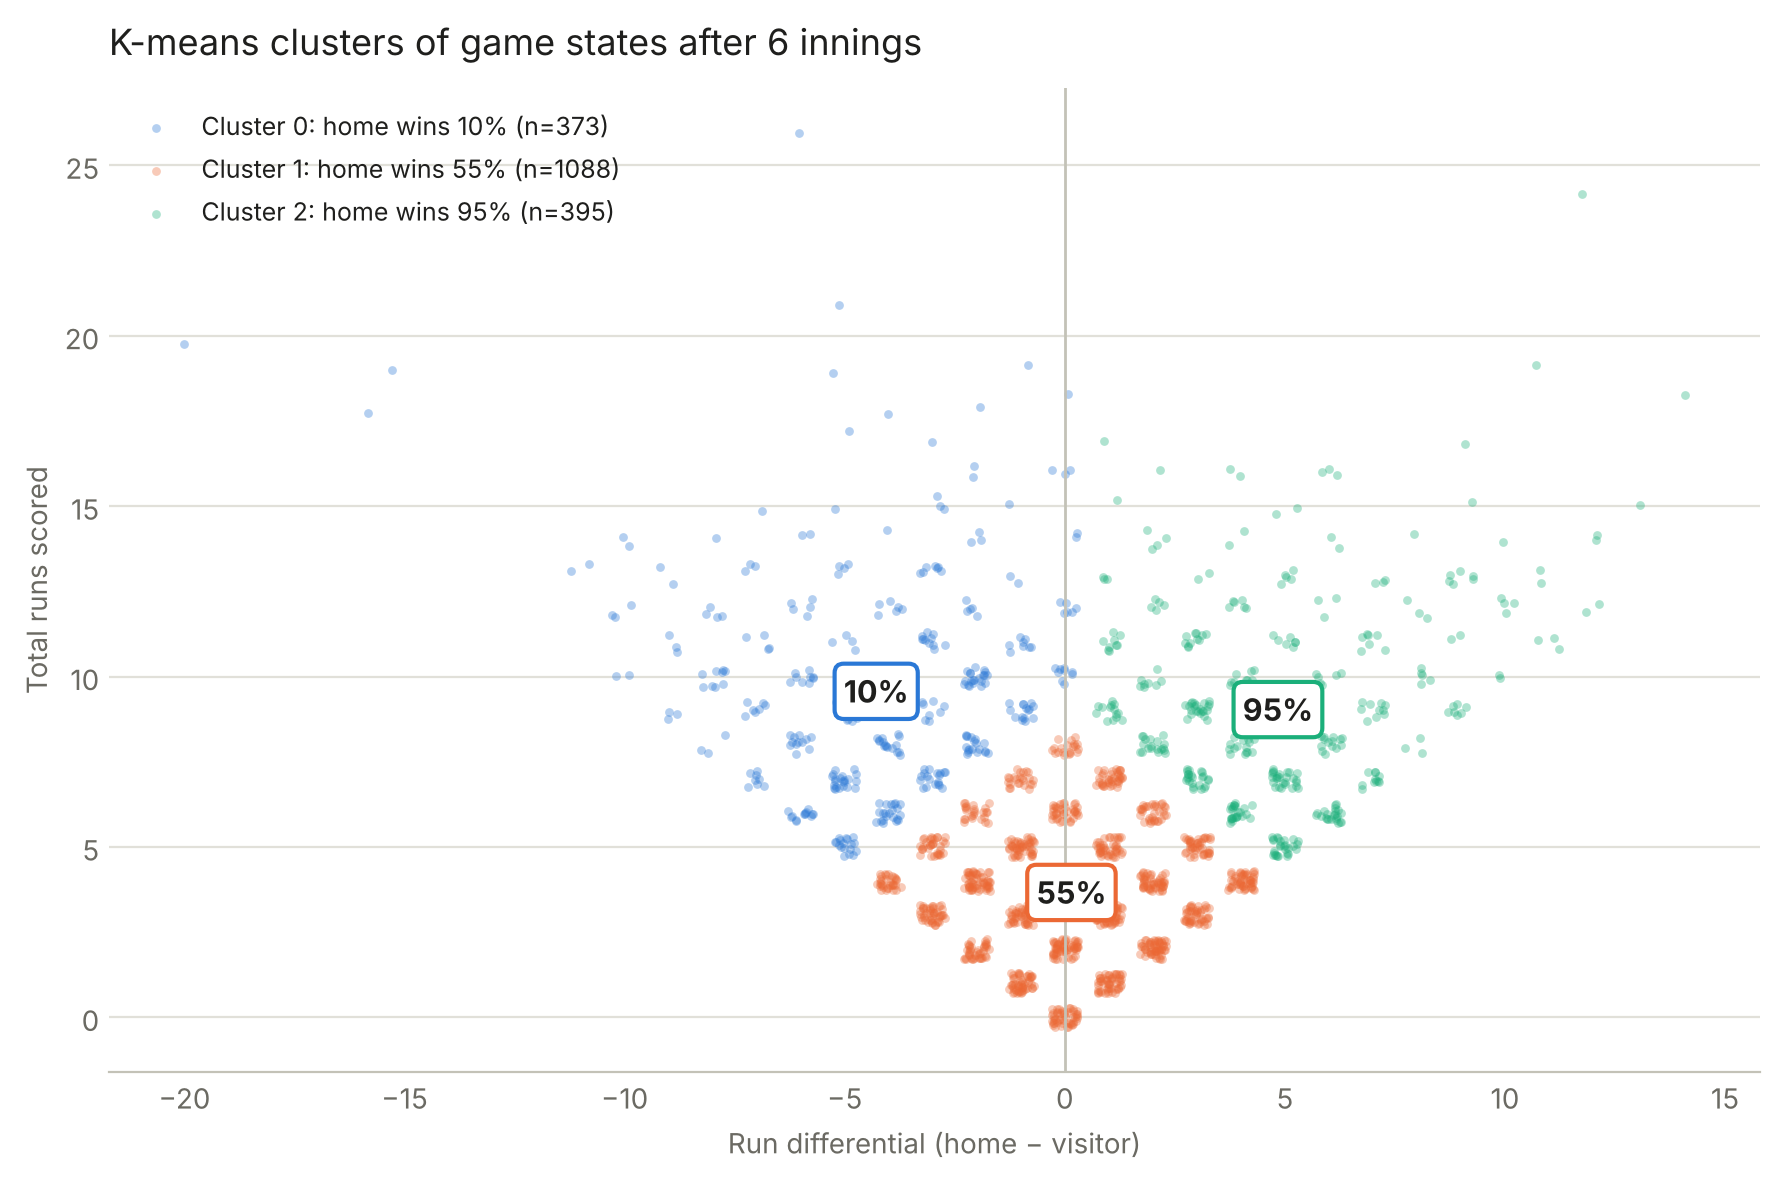

  saved figures/1_kmeans_clusters.png


In [38]:
km_model = fit_kmeans(train)
display(km_model["summary"].round(3))
plot_kmeans(km_model, train, OUT_DIR)

## 4b. Supervised 1: lookup table
The home team's actual win rate at each run differential (leads of 6+ either way are pooled).

In [39]:
def fit_lookup(train: pd.DataFrame, cap: int = DIFF_CAP) -> pd.DataFrame:
    """Home-win rate for each run differential (pooled beyond +/-cap)."""
    d = train["run_diff"].clip(-cap, cap)
    table = (train.assign(diff_bin=d).groupby("diff_bin")
             .agg(games=("gid", "size"), home_win_rate=("home_win", "mean")))
    return table


def predict_lookup(table: pd.DataFrame, df: pd.DataFrame, cap: int = DIFF_CAP) -> np.ndarray:
    overall = (table["home_win_rate"] * table["games"]).sum() / table["games"].sum()
    p = df["run_diff"].clip(-cap, cap).map(table["home_win_rate"]).fillna(overall)
    return p.to_numpy()


def plot_lookup(table: pd.DataFrame, out_dir: str, cap: int = DIFF_CAP):
    names = [f"≤{-cap}" if i == -cap else f"≥+{cap}" if i == cap else "0" if i == 0 else f"{i:+d}"
             for i in table.index]
    labels = [f"{nm}\nn={n}" for nm, n in zip(names, table["games"])]
    colors = [HOME_COLOR if r >= 0.5 else AWAY_COLOR for r in table["home_win_rate"]]

    fig, ax = plt.subplots(figsize=(10, 5.5))
    bars = ax.bar(labels, table["home_win_rate"], color=colors, width=0.7)
    for b, r in zip(bars, table["home_win_rate"]):
        ax.text(b.get_x() + b.get_width() / 2, r + 0.015, f"{r:.0%}", ha="center", fontsize=9, color=INK)
    ax.axhline(0.5, color=INK_MUTED, lw=1, ls="--")
    ax.set_ylim(0, 1.08)
    ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
    style_axes(ax, "Home win % by run differential after 6 innings (lookup table)",
               "Run differential (home − visitor), with # of games", "Home team win %")
    ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=HOME_COLOR),
                       plt.Rectangle((0, 0), 1, 1, color=AWAY_COLOR)],
              labels=["Home team favored", "Visitor favored"], frameon=False, loc="upper left")
    save(fig, out_dir, "2_lookup_table.png")

,games,home_win_rate
diff_bin,,
-6,102,0.029
-5,66,0.000
-4,89,0.034
-3,126,0.079
-2,170,0.176
-1,196,0.316
0,250,0.544
1,213,0.732
2,174,0.879


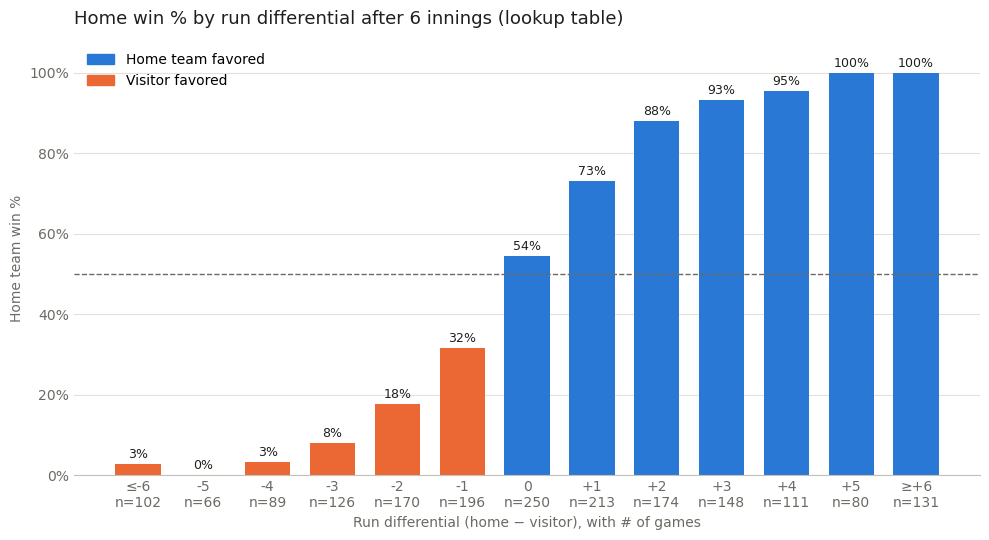

  saved figures\2_lookup_table.png


In [40]:
lookup = fit_lookup(train)
display(lookup.round(3))
plot_lookup(lookup, OUT_DIR)

## 4c. Supervised 2: logistic regression
Models `home_win ~ run_diff + total_runs`.

In [25]:
LR_FEATURES = ["run_diff", "total_runs"]


def fit_logistic(train: pd.DataFrame) -> LogisticRegression:
    model = LogisticRegression().fit(train[LR_FEATURES], train["home_win"])
    coefs = dict(zip(LR_FEATURES, model.coef_[0]))
    print(f"  intercept={model.intercept_[0]:.3f}  " +
          "  ".join(f"{k}={v:.3f}" for k, v in coefs.items()))
    print(f"  each extra run of home lead multiplies the home team's odds of winning by "
          f"{np.exp(coefs['run_diff']):.2f}x")
    return model


def predict_logistic(model, df: pd.DataFrame) -> np.ndarray:
    return model.predict_proba(df[LR_FEATURES])[:, 1]


def plot_logistic(model, train: pd.DataFrame, out_dir: str):
    observed = train.groupby("run_diff").agg(games=("gid", "size"), rate=("home_win", "mean"))
    observed = observed[observed["games"] >= 10]  # hide very noisy points
    xs = np.arange(train["run_diff"].min(), train["run_diff"].max() + 1)
    curve = predict_logistic(model, pd.DataFrame({
        "run_diff": xs, "total_runs": train["total_runs"].median()}))

    fig, ax = plt.subplots(figsize=(9, 5.5))
    ax.scatter(observed.index, observed["rate"], s=np.clip(observed["games"] / 4, 12, 200),
               color=AWAY_COLOR, alpha=0.8, edgecolors="white", linewidths=1.5,
               label="Observed win % (size = # games)", zorder=3)
    ax.plot(xs, curve, color=HOME_COLOR, lw=2,
            label=f"Logistic regression (total runs = {train['total_runs'].median():.0f})")
    ax.axhline(0.5, color=INK_MUTED, lw=1, ls="--")
    ax.set_ylim(-0.02, 1.02)
    ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
    style_axes(ax, "Predicted home win probability after 6 innings",
               "Run differential (home − visitor)", "Home team win %")
    ax.legend(frameon=False, loc="upper left")
    save(fig, out_dir, "3_logistic_regression.png")

  intercept=0.152  run_diff=0.846  total_runs=0.001
  each extra run of home lead multiplies the home team's odds of winning by 2.33x


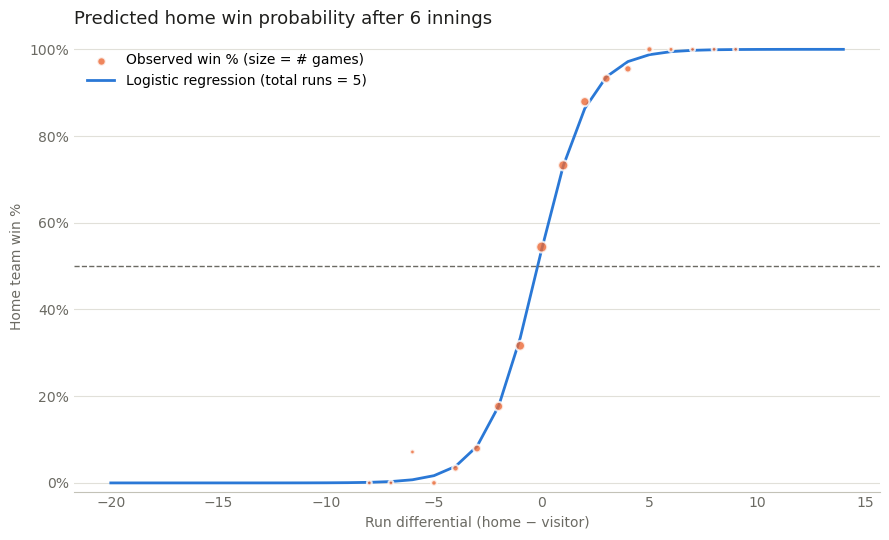

  saved figures\3_logistic_regression.png


In [26]:
lr_model = fit_logistic(train)
plot_logistic(lr_model, train, OUT_DIR)

## 5. Compare models and predict
All three models scored on the same held-out games. Lower log loss and Brier mean better probabilities. The calibration chart checks that a predicted 70% actually wins about 70% of the time.

In [27]:
def evaluate(name: str, y_true, p_home) -> dict:
    p = np.clip(p_home, 1e-6, 1 - 1e-6)  # avoid log(0) for 0%/100% lookup cells
    return {"model": name,
            "accuracy": accuracy_score(y_true, p >= 0.5),
            "log_loss": log_loss(y_true, p),
            "brier": brier_score_loss(y_true, p)}


def plot_comparison(results: pd.DataFrame, test: pd.DataFrame, preds: dict, out_dir: str):
    """Calibration: does a predicted 70% actually win ~70% of the time?"""
    fig, ax = plt.subplots(figsize=(7, 6))
    ax.plot([0, 1], [0, 1], color=AXIS, lw=1, ls="--", label="Perfect calibration")
    bins = np.linspace(0, 1, 11)
    for (name, p), color in zip(preds.items(), CLUSTER_COLORS):
        b = np.digitize(p, bins[1:-1])
        cal = pd.DataFrame({"b": b, "p": p, "y": test["home_win"].to_numpy()}).groupby("b").mean()
        ax.plot(cal["p"], cal["y"], marker="o", ms=8, lw=2, color=color,
                markeredgecolor="white", markeredgewidth=1.5, label=name)
    ax.xaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
    ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
    style_axes(ax, "Calibration on held-out games", "Predicted home win %", "Actual home win %")
    ax.legend(frameon=False, loc="upper left")
    save(fig, out_dir, "4_model_calibration.png")


def predict_game(score_v: int, score_h: int, km_model, lookup, lr_model) -> pd.DataFrame:
    """Predicted winner + win % from each model for one score after 6 innings."""
    row = pd.DataFrame({"run_diff": [score_h - score_v], "total_runs": [score_h + score_v]})
    out = []
    for name, p in [("K-means", predict_kmeans(km_model, row)[0]),
                    ("Lookup table", predict_lookup(lookup, row)[0]),
                    ("Logistic regression", predict_logistic(lr_model, row)[0])]:
        winner = "Home" if p >= 0.5 else "Visitor"
        out.append({"model": name, "predicted_winner": winner,
                    "win_pct": f"{max(p, 1 - p):.1%}"})
    return pd.DataFrame(out)


# ---------------------------------------------------------------------------

,model,accuracy,log_loss,brier
0,K-means,0.7092,0.5084,0.1721
1,Lookup table,0.8304,0.4102,0.1199
2,Logistic regression,0.8304,0.3819,0.1202


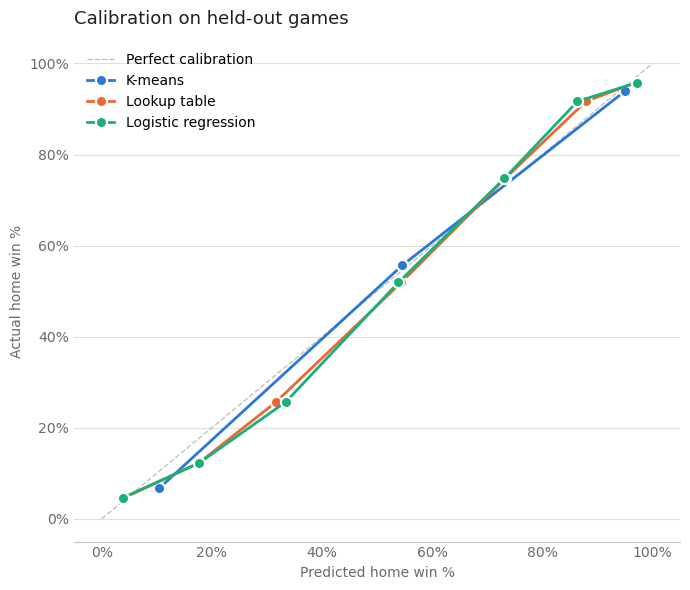

  saved figures\4_model_calibration.png


In [28]:
preds = {"K-means": predict_kmeans(km_model, test),
         "Lookup table": predict_lookup(lookup, test),
         "Logistic regression": predict_logistic(lr_model, test)}
results = pd.DataFrame([evaluate(n, test["home_win"], p) for n, p in preds.items()])
display(results.round(4))
plot_comparison(results, test, preds, OUT_DIR)

### Predict a game
Enter the score after 6 innings (visitor, home).

In [29]:
for v, h in [(3, 1), (2, 2), (1, 4)]:
    print(f"After 6 innings: Visitor {v}, Home {h}")
    display(predict_game(v, h, km_model, lookup, lr_model))

After 6 innings: Visitor 3, Home 1


,model,predicted_winner,win_pct
0,K-means,Home,54.6%
1,Lookup table,Visitor,82.4%
2,Logistic regression,Visitor,82.3%


After 6 innings: Visitor 2, Home 2


,model,predicted_winner,win_pct
0,K-means,Home,54.6%
1,Lookup table,Home,54.4%
2,Logistic regression,Home,53.9%


After 6 innings: Visitor 1, Home 4


,model,predicted_winner,win_pct
0,K-means,Home,54.6%
1,Lookup table,Home,93.2%
2,Logistic regression,Home,93.7%
